# Experiment No. 9
## K-Means Clustering for Customer Segmentation

### Aim
To implement the K-Means Clustering algorithm on the Mall Customers
dataset and group customers into meaningful clusters based on their
characteristics.

### Dataset
Mall Customers Dataset

### Problem Statement
To segment customers into different groups based on their Annual Income
and Spending Score using the K-Means Clustering algorithm.

### Objectives

1. To study and understand the K-Means Clustering algorithm.
2. To perform exploratory data analysis on the Mall Customers dataset.
3. To determine the optimal number of clusters using the Elbow Method.
4. To apply K-Means Clustering for customer segmentation.
5. To visualize and analyze the generated customer clusters.

### Theory

K-Means Clustering is an unsupervised machine learning algorithm used to
partition a dataset into K distinct clusters based on similarity. Unlike
supervised learning, K-Means does not require predefined target labels.

The algorithm begins by selecting K initial centroids. Each data point is
assigned to the nearest centroid using a distance measure, generally
Euclidean distance. The centroids are then recalculated using the mean of
the points assigned to each cluster. This process is repeated until the
clusters become stable or the algorithm converges.

In this experiment, K-Means Clustering is applied to the Mall Customers
dataset to identify customer segments based mainly on Annual Income and
Spending Score.

### Elbow Method

The Elbow Method is used to determine a suitable value of K. It calculates
the Within-Cluster Sum of Squares (WCSS) for different values of K. The
value of K at which the decrease in WCSS becomes significantly smaller is
considered the elbow point and is selected as the suitable number of clusters.

In [46]:
# Set OpenMP threads to avoid the Windows MKL K-Means warning
import os
os.environ["OMP_NUM_THREADS"] = "1"

print("OpenMP thread limit set successfully.")

OpenMP thread limit set successfully.


In [47]:
# Import libraries required for data analysis, visualization and K-Means clustering

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [48]:
# Load the Mall Customers dataset from the specified file path

file_path = r"C:\Users\USER\Downloads\Mall_Customers (1).csv"

df = pd.read_csv(file_path)

print("Mall Customers dataset loaded successfully.")

Mall Customers dataset loaded successfully.


In [49]:
# Display the first five records of the dataset

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [50]:
# Display the number of rows and columns in the dataset

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 200
Number of columns: 5
Dataset shape: (200, 5)


In [51]:
# Display information about columns, data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [52]:
# Display the column names of the dataset

print("Column names:")
print(df.columns.tolist())

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [53]:
# Generate descriptive statistics for numerical features

df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [54]:
# Check for missing values in the dataset

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total missing values: 0


In [55]:
# Check for duplicate records in the dataset

print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


* Exploratory Data Analysis

In [56]:
# Count customers belonging to each gender category

gender_counts = df["Gender"].value_counts()

print("Gender distribution:")
print(gender_counts)

Gender distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64


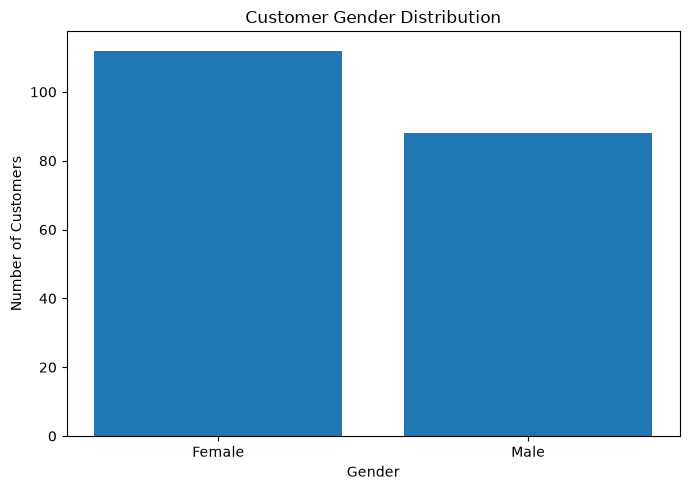

In [57]:
# Visualize the distribution of customers by gender

plt.figure(figsize=(7, 5))

plt.bar(
    gender_counts.index,
    gender_counts.values
)

plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.title("Customer Gender Distribution")

plt.tight_layout()
plt.show()

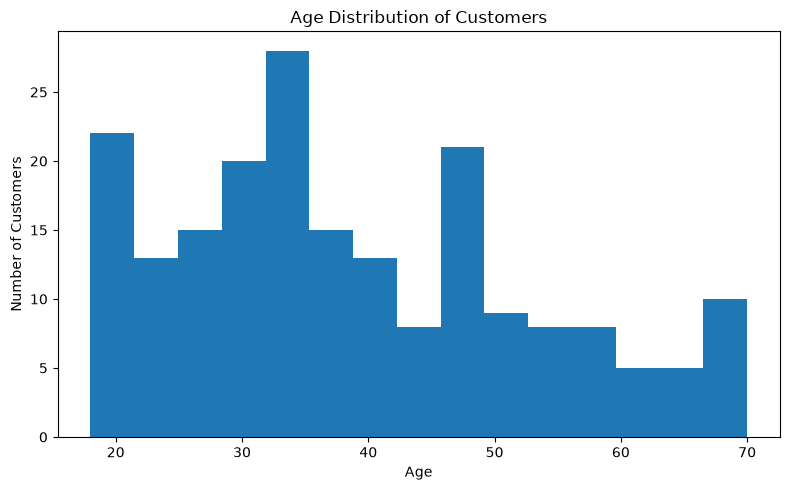

In [58]:
# Visualize the age distribution of customers

plt.figure(figsize=(8, 5))

plt.hist(
    df["Age"],
    bins=15
)

plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.title("Age Distribution of Customers")

plt.tight_layout()
plt.show()

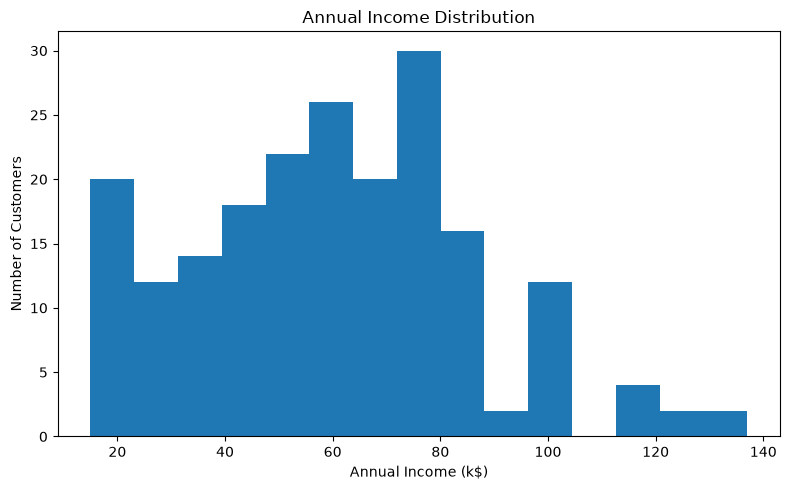

In [59]:
# Visualize the distribution of annual income

plt.figure(figsize=(8, 5))

plt.hist(
    df["Annual Income (k$)"],
    bins=15
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.title("Annual Income Distribution")

plt.tight_layout()
plt.show()

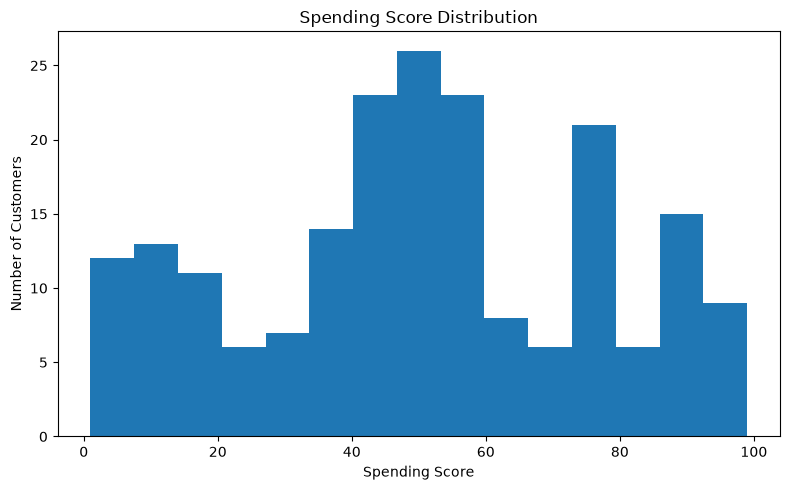

In [60]:
# Visualize the distribution of customer spending scores

plt.figure(figsize=(8, 5))

plt.hist(
    df["Spending Score (1-100)"],
    bins=15
)

plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")
plt.title("Spending Score Distribution")

plt.tight_layout()
plt.show()

* Selecting Features for Clustering

In [61]:
# Select Annual Income and Spending Score for customer clustering

X = df[
    [
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
]

print("Selected features:")
print(X.columns.tolist())

print("\nFirst five records:")
display(X.head())

Selected features:
['Annual Income (k$)', 'Spending Score (1-100)']

First five records:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [62]:
# Display descriptive statistics of the selected clustering features

X.describe()

,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000
mean,60.560000,50.200000
std,26.264721,25.823522
min,15.000000,1.000000
25%,41.500000,34.750000
50%,61.500000,50.000000
75%,78.000000,73.000000
max,137.000000,99.000000


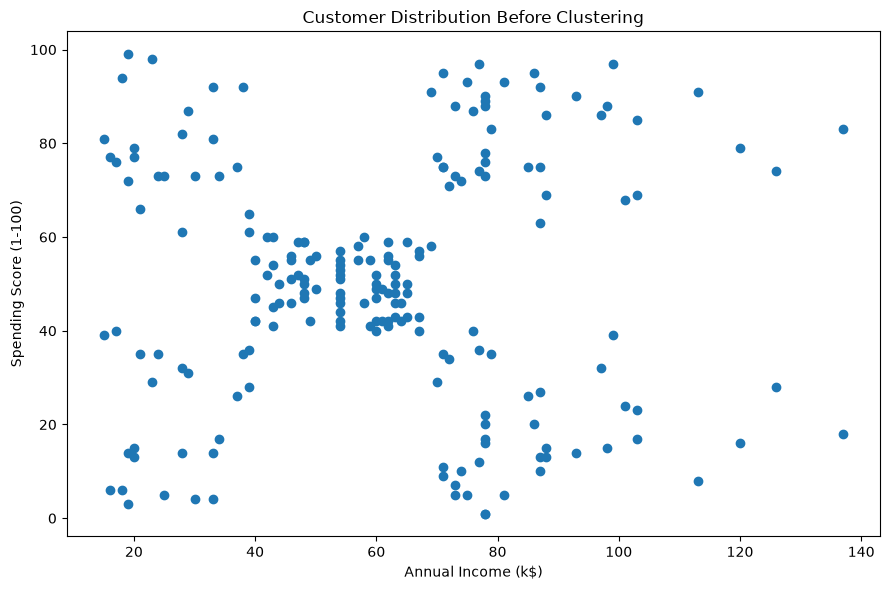

In [63]:
# Visualize customers based on Annual Income and Spending Score before clustering

plt.figure(figsize=(9, 6))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"]
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Distribution Before Clustering")

plt.tight_layout()
plt.show()

* Preprocessing

In [64]:
# Standardize the selected features before applying K-Means

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


In [65]:
# Display the first five standardized observations

scaled_data = pd.DataFrame(
    X_scaled,
    columns=[
        "Annual Income Scaled",
        "Spending Score Scaled"
    ]
)

scaled_data.head()

,Annual Income Scaled,Spending Score Scaled
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


* Finding Optimal K

In [84]:
# Calculate WCSS for different numbers of clusters using the Elbow Method

import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak on Windows with MKL")

wcss = []

for k in range(1, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    
    wcss.append(kmeans.inertia_)

print("WCSS values:")
print(wcss)

WCSS values:
[400.0, 269.69101219276394, 157.70400815035947, 108.92131661364357, 65.56840815571681, 55.057348270386, 44.86475569922557, 37.228187677585886, 32.392267630331176, 29.981897788243693]


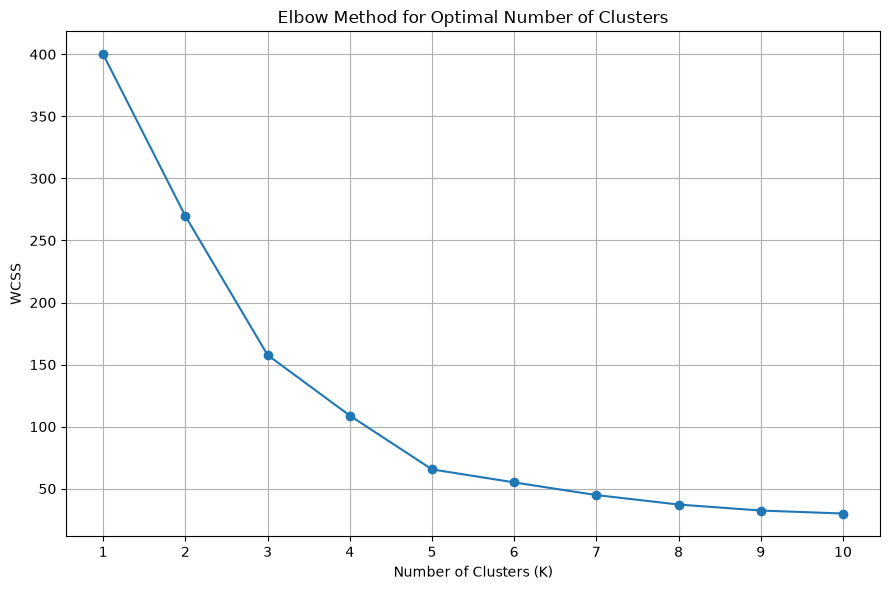

In [67]:
# Plot the Elbow Curve to determine the optimal number of clusters

plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal Number of Clusters")

plt.xticks(range(1, 11))
plt.grid()

plt.tight_layout()
plt.show()

In [68]:
# Create the K-Means clustering model with five clusters

kmeans_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

print("K-Means model created successfully.")

K-Means model created successfully.


In [69]:
# Fit the K-Means model to the scaled customer data

kmeans_model.fit(X_scaled)

print("K-Means clustering completed successfully.")

C:\Users\USER\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-Means clustering completed successfully.


In [70]:
# Assign each customer to its corresponding cluster

cluster_labels = kmeans_model.labels_

print("Cluster labels generated successfully.")
print("\nFirst 20 cluster labels:")
print(cluster_labels[:20])

Cluster labels generated successfully.

First 20 cluster labels:
[4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2]


In [71]:
# Add the cluster labels to the original dataset

df["Cluster"] = cluster_labels

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [72]:
# Count the number of customers assigned to each cluster

cluster_counts = df["Cluster"].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [73]:
# Convert cluster centers back to the original feature scale

cluster_centers_scaled = kmeans_model.cluster_centers_

cluster_centers = scaler.inverse_transform(
    cluster_centers_scaled
)

cluster_centers_df = pd.DataFrame(
    cluster_centers,
    columns=[
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
)

cluster_centers_df.round(2)

,Annual Income (k$),Spending Score (1-100)
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


* Cluster Visualization

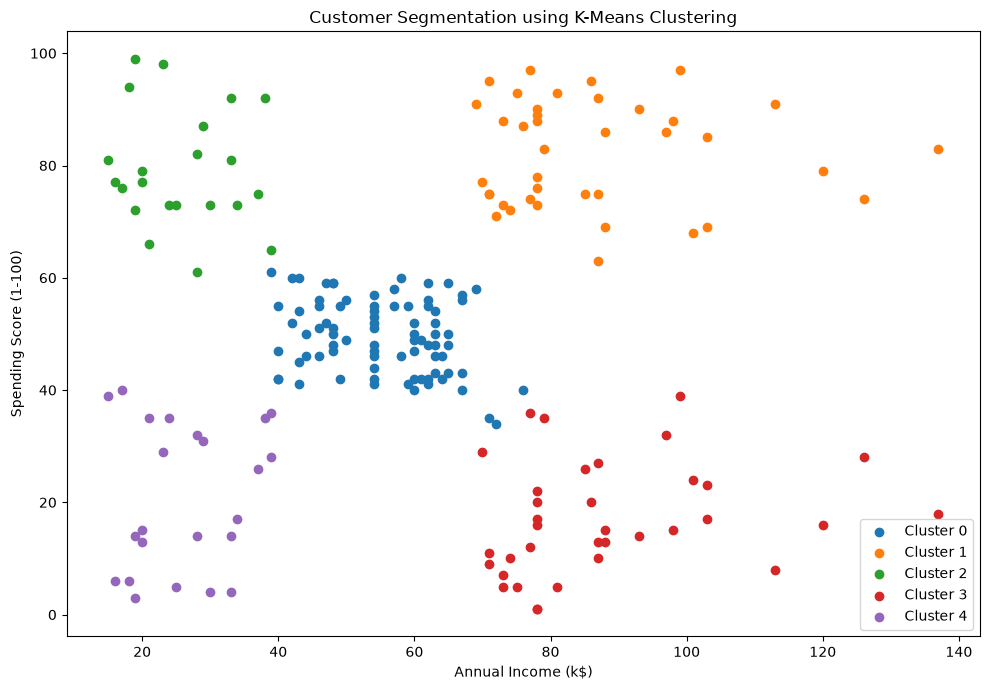

In [74]:
# Visualize the customer clusters based on Annual Income and Spending Score

plt.figure(figsize=(10, 7))

for cluster in range(5):
    
    cluster_data = df[df["Cluster"] == cluster]
    
    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation using K-Means Clustering")

plt.legend()
plt.tight_layout()
plt.show()

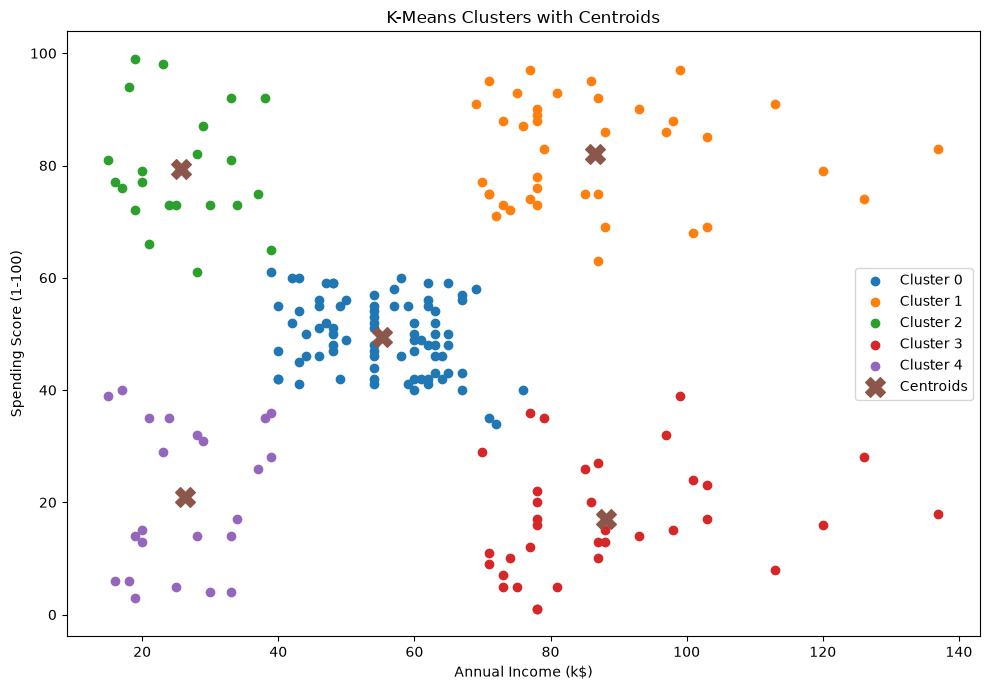

In [75]:
# Visualize customer clusters together with their centroids

plt.figure(figsize=(10, 7))

for cluster in range(5):
    
    cluster_data = df[df["Cluster"] == cluster]
    
    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.scatter(
    cluster_centers[:, 0],
    cluster_centers[:, 1],
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clusters with Centroids")

plt.legend()
plt.tight_layout()
plt.show()

* Cluster Analysis

In [76]:
# Calculate the average customer characteristics for each cluster

cluster_profile = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean"
}).round(2)

cluster_profile

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


In [77]:
# Calculate the number of customers present in each cluster

cluster_size = df.groupby("Cluster").size().reset_index(
    name="Number of Customers"
)

cluster_size

,Cluster,Number of Customers
0,0,81
1,1,39
2,2,22
3,3,35
4,4,23


In [78]:
# Create a complete profile containing cluster size and average characteristics

complete_profile = df.groupby("Cluster").agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

complete_profile

,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


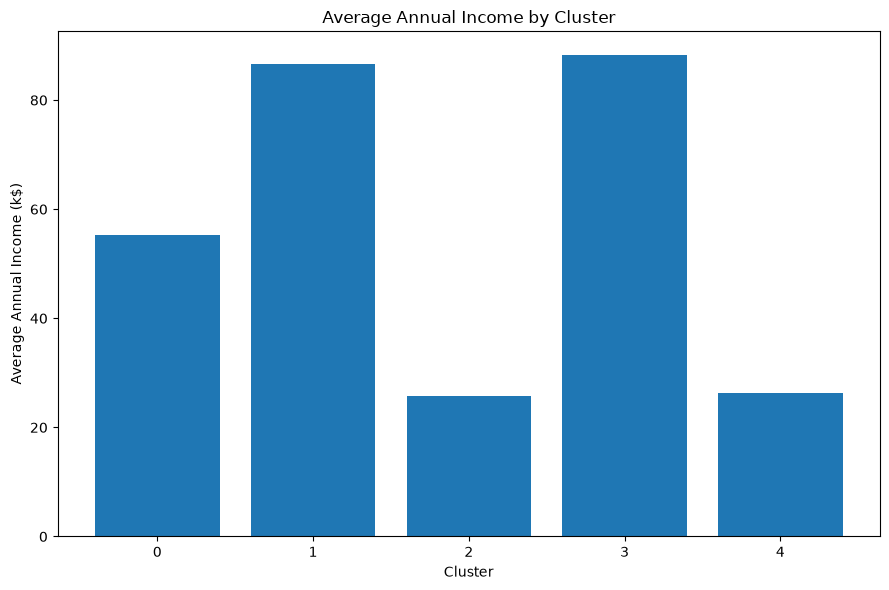

In [79]:
# Compare average annual income across customer clusters

plt.figure(figsize=(9, 6))

plt.bar(
    complete_profile.index.astype(str),
    complete_profile["Average_Income"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Annual Income (k$)")
plt.title("Average Annual Income by Cluster")

plt.tight_layout()
plt.show()

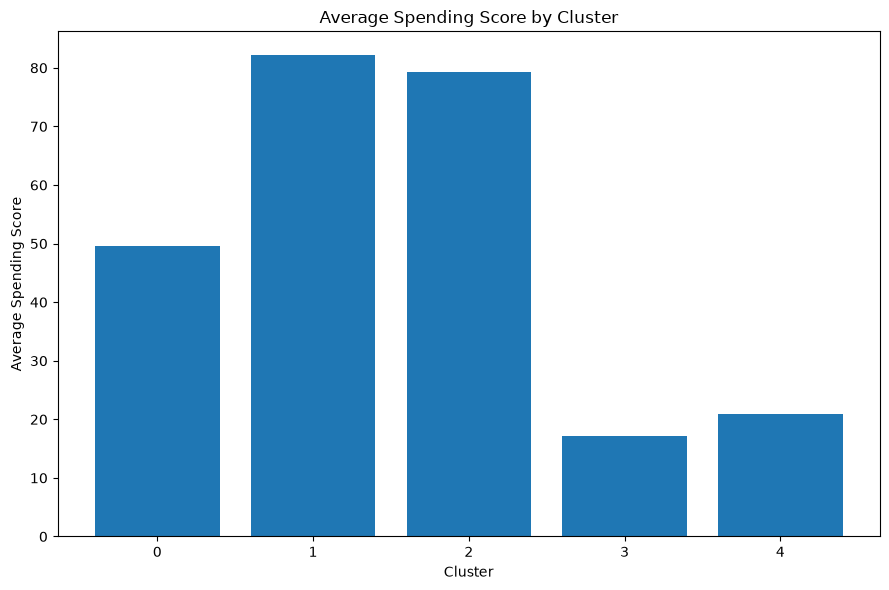

In [80]:
# Compare average spending score across customer clusters

plt.figure(figsize=(9, 6))

plt.bar(
    complete_profile.index.astype(str),
    complete_profile["Average_Spending_Score"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Spending Score")
plt.title("Average Spending Score by Cluster")

plt.tight_layout()
plt.show()

In [81]:
# Display the customer records along with their assigned cluster

df.head(20)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


In [82]:
# Save the final customer segmentation results into a CSV file

output_path = r"C:\Users\USER\Downloads\Mall_Customers_Clustered.csv"

df.to_csv(
    output_path,
    index=False
)

print("Clustered dataset saved successfully.")
print("Saved file:", output_path)

Clustered dataset saved successfully.
Saved file: C:\Users\USER\Downloads\Mall_Customers_Clustered.csv


* Final Result

In [83]:
# Display the final result of the K-Means clustering experiment

print("=" * 65)
print("FINAL K-MEANS CLUSTERING RESULT")
print("=" * 65)

print("\nDataset             : Mall Customers")
print("Algorithm           : K-Means Clustering")
print("Number of Clusters  : 5")
print("Clustering Features : Annual Income and Spending Score")

print("\nCluster Sizes:")
print(cluster_counts)

print("\nCluster Centers:")
display(cluster_centers_df.round(2))

FINAL K-MEANS CLUSTERING RESULT

Dataset             : Mall Customers
Algorithm           : K-Means Clustering
Number of Clusters  : 5
Clustering Features : Annual Income and Spending Score

Cluster Sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster Centers:


,Annual Income (k$),Spending Score (1-100)
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


### Conclusion

In this experiment, the K-Means Clustering algorithm was successfully
implemented on the Mall Customers dataset for customer segmentation.

Annual Income and Spending Score were selected as the primary clustering
features. The Elbow Method was used to determine a suitable number of
clusters, after which K-Means was applied to divide customers into five
distinct groups.

The resulting clusters were visualized using scatter plots and analyzed
using their average age, income and spending score. The experiment
demonstrates how unsupervised machine learning can be used to discover
hidden patterns in customer data and support data-driven customer
segmentation and marketing decisions.